# Phase 4 — Similarity Engine

**Inputs:** `outputs/audio_features.parquet` + `outputs/lyrics_features.parquet`  
**Outputs:** `outputs/faiss_index/` + `outputs/coherence_scores.parquet`

## Four fusion strategies

| Strategy | Vectors | Index size |
|---|---|---|
| Audio-only | CLAP normalized (512-dim) | 3,232 tracks |
| Lyrics-only | SBERT normalized (768-dim) | 2,075 tracks |
| Early fusion | L2-norm([CLAP_raw; SBERT_raw]) (1,280-dim) | 2,075 tracks |
| Late fusion | α × audio_sim + (1-α) × lyrics_sim at query time | — |

**Early fusion uses the raw (un-normalized) projections** from Phase 2 (`audio_clap_raw`) and
Phase 3 (`lyrics_sbert_raw`). If both streams are unit-normalized before concatenation, the
1,280-dim vector re-normalizes to `[c/√2; s/√2]` and the inner product equals
`0.5·cosine_audio + 0.5·cosine_lyrics` — identical to late fusion at α=0.5. Raw projections
have different natural scales, so the concatenation is non-trivially weighted.

## Novel contribution — Cross-modal coherence score (4b)
For each multimodal track, project audio (CLAP) and lyrics (SBERT) independently to the  
shared AV space using Ridge regression trained on the 70/15/15 training split.  
**Coherence = cosine similarity between audio-predicted AV and lyrics-predicted AV.**  
Low coherence → "emotional paradox" (upbeat sound, dark lyrics or vice versa).

## Required packages
```
pip install faiss-cpu scikit-learn
```

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import faiss
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR   = os.path.join(ROOT, 'outputs')
FAISS_DIR = os.path.join(OUT_DIR, 'faiss_index')
os.makedirs(FAISS_DIR, exist_ok=True)

QUADRANT_COLORS = {'Q1': '#f4a261', 'Q2': '#e63946', 'Q3': '#457b9d', 'Q4': '#2a9d8f'}
QUADRANT_LABELS = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad',   'Q4': 'Calm'}

print(f'FAISS version: {faiss.__version__}')
print(f'Output dir: {FAISS_DIR}')

FAISS version: 1.13.2
Output dir: <ROOT>\outputs\faiss_index


## 1. Load Features & Build Multimodal Join

In [2]:
# ── Audio features (3,232 tracks) ────────────────────────────────────────────
audio_df      = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet'))
clap_arr      = np.vstack(audio_df['audio_clap'].values).astype(np.float32)         # (3232, 512) normalized
clap_raw_arr  = np.vstack(audio_df['audio_clap_raw'].values).astype(np.float32)     # (3232, 512) un-normalized
hc_arr        = np.vstack(audio_df['audio_handcrafted'].values).astype(np.float32)  # (3232, 141)
print(f'Audio:  {audio_df.shape}  CLAP={clap_arr.shape}  CLAP_raw={clap_raw_arr.shape}  HC={hc_arr.shape}')

# ── Lyrics features (2,075 tracks) ───────────────────────────────────────────
lyrics_df      = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
sbert_arr      = np.vstack(lyrics_df['lyrics_sbert'].values).astype(np.float32)     # (2075, 768) normalized
sbert_raw_arr  = np.vstack(lyrics_df['lyrics_sbert_raw'].values).astype(np.float32) # (2075, 768) un-normalized
nrc_arr        = np.vstack(lyrics_df['lyrics_nrc'].values).astype(np.float32)       # (2075, 10)
print(f'Lyrics: {lyrics_df.shape}  SBERT={sbert_arr.shape}  SBERT_raw={sbert_raw_arr.shape}  NRC={nrc_arr.shape}')

# ── Multimodal join (tracks in both) ─────────────────────────────────────────
mm_df = audio_df[['song_id','quadrant','arousal','valence']].merge(
    lyrics_df[['song_id']],
    on='song_id', how='inner'
).reset_index(drop=True)

# Aligned arrays for multimodal subset
audio_idx_map  = {sid: i for i, sid in enumerate(audio_df['song_id'])}
lyrics_idx_map = {sid: i for i, sid in enumerate(lyrics_df['song_id'])}

mm_audio_rows  = [audio_idx_map[sid]  for sid in mm_df['song_id']]
mm_lyrics_rows = [lyrics_idx_map[sid] for sid in mm_df['song_id']]

mm_clap      = clap_arr[mm_audio_rows]          # (2075, 512) normalized
mm_clap_raw  = clap_raw_arr[mm_audio_rows]      # (2075, 512) un-normalized
mm_sbert     = sbert_arr[mm_lyrics_rows]         # (2075, 768) normalized
mm_sbert_raw = sbert_raw_arr[mm_lyrics_rows]     # (2075, 768) un-normalized
mm_av        = mm_df[['arousal','valence']].values.astype(np.float32)  # (2075, 2)

print(f'\nMultimodal: {len(mm_df)} tracks')
print(f'  mm_clap={mm_clap.shape}  mm_clap_raw={mm_clap_raw.shape}')
print(f'  mm_sbert={mm_sbert.shape}  mm_sbert_raw={mm_sbert_raw.shape}')

# Sanity: confirm raw norms are non-uniform (not unit-normalized)
clap_raw_norms  = np.linalg.norm(mm_clap_raw,  axis=1)
sbert_raw_norms = np.linalg.norm(mm_sbert_raw, axis=1)
print(f'\n  CLAP_raw norms:  mean={clap_raw_norms.mean():.4f}  std={clap_raw_norms.std():.4f}')
print(f'  SBERT_raw norms: mean={sbert_raw_norms.mean():.4f}  std={sbert_raw_norms.std():.4f}')

Audio:  (3232, 7)  CLAP=(3232, 512)  CLAP_raw=(3232, 512)  HC=(3232, 141)
Lyrics: (2075, 8)  SBERT=(2075, 768)  SBERT_raw=(2075, 768)  NRC=(2075, 10)

Multimodal: 2075 tracks
  mm_clap=(2075, 512)  mm_clap_raw=(2075, 512)
  mm_sbert=(2075, 768)  mm_sbert_raw=(2075, 768)

  CLAP_raw norms:  mean=0.3863  std=0.0558
  SBERT_raw norms: mean=2.4959  std=0.1372


In [3]:
# ── Load 70/15/15 tvt splits ──────────────────────────────────────────────────
TVT = 'tvt_70_15_15'

def load_split(root, split_name, subset):
    fname = f'{split_name}_{subset}_{"audio" if "Audio" in root else "lyrics"}_balanced.csv'
    path  = os.path.join(ROOT, root, 'tvt_dataframes', split_name, fname)
    return set(pd.read_csv(path)['Song'].tolist())

audio_train = load_split('MERGE_Audio_Balanced',  TVT, 'train')
audio_val   = load_split('MERGE_Audio_Balanced',  TVT, 'validate')
audio_test  = load_split('MERGE_Audio_Balanced',  TVT, 'test')

lyrics_train = load_split('MERGE_Lyrics_Balanced', TVT, 'train')
lyrics_val   = load_split('MERGE_Lyrics_Balanced', TVT, 'validate')
lyrics_test  = load_split('MERGE_Lyrics_Balanced', TVT, 'test')

print(f'Audio  split (70/15/15): train={len(audio_train)}  val={len(audio_val)}  test={len(audio_test)}')
print(f'Lyrics split (70/15/15): train={len(lyrics_train)} val={len(lyrics_val)} test={len(lyrics_test)}')

# Multimodal train mask (tracks in BOTH audio train and lyrics train)
mm_train_mask = mm_df['song_id'].isin(audio_train).values
mm_test_mask  = mm_df['song_id'].isin(audio_test).values
print(f'\nMultimodal in audio train: {mm_train_mask.sum()}')
print(f'Multimodal in audio test:  {mm_test_mask.sum()}')

Audio  split (70/15/15): train=2264  val=484  test=484
Lyrics split (70/15/15): train=1680 val=360 test=360

Multimodal in audio train: 1278
Multimodal in audio test:  397


## 2. Cross-Modal Coherence Score (4b)

Train two independent Ridge regressors on the training split:
- **Audio projector:** CLAP (512-dim) → (arousal, valence)
- **Lyrics projector:** SBERT (768-dim) → (arousal, valence)

For each multimodal track, both projectors make a 2D AV prediction.  
**Coherence = cosine_sim(audio_AV_pred, lyrics_AV_pred)**

- **High coherence (+1):** audio and lyrics agree on emotion quadrant
- **Low/negative (→−1):** audio and lyrics pull in opposite AV directions — "emotional paradox"

In [4]:
# Training data for AV projectors
X_clap_train  = mm_clap[mm_train_mask]
X_sbert_train = mm_sbert[mm_train_mask]
y_train       = mm_av[mm_train_mask]

print(f'Projector training set: {X_clap_train.shape[0]} multimodal tracks')

# Ridge with cross-validated alpha: searches [0.01, 0.1, 1, 10, 100, 1000]
ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

audio_proj = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge',  RidgeCV(alphas=ALPHAS)),
])
lyrics_proj = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge',  RidgeCV(alphas=ALPHAS)),
])

audio_proj.fit(X_clap_train,  y_train)
lyrics_proj.fit(X_sbert_train, y_train)

print(f'Audio  projector best alpha: {audio_proj["ridge"].alpha_:.3f}')
print(f'Lyrics projector best alpha: {lyrics_proj["ridge"].alpha_:.3f}')

# Validation R²
mm_val_mask = mm_df['song_id'].isin(audio_val).values
X_clap_val  = mm_clap[mm_val_mask]
X_sbert_val = mm_sbert[mm_val_mask]
y_val       = mm_av[mm_val_mask]

r2_audio  = r2_score(y_val, audio_proj.predict(X_clap_val),  multioutput='uniform_average')
r2_lyrics = r2_score(y_val, lyrics_proj.predict(X_sbert_val), multioutput='uniform_average')
print(f'\nValidation R² (arousal+valence, uniform avg):')
print(f'  Audio  projector (CLAP→AV):  {r2_audio:.3f}')
print(f'  Lyrics projector (SBERT→AV): {r2_lyrics:.3f}')

Projector training set: 1278 multimodal tracks
Audio  projector best alpha: 1000.000
Lyrics projector best alpha: 1000.000

Validation R² (arousal+valence, uniform avg):
  Audio  projector (CLAP→AV):  0.166
  Lyrics projector (SBERT→AV): 0.345


In [5]:
# Project ALL multimodal tracks
av_from_audio  = audio_proj.predict(mm_clap).astype(np.float32)   # (2075, 2)
av_from_lyrics = lyrics_proj.predict(mm_sbert).astype(np.float32) # (2075, 2)

def batch_cosine_sim(A, B):
    """Row-wise cosine similarity between two (N, D) arrays."""
    norm_a = np.linalg.norm(A, axis=1, keepdims=True) + 1e-8
    norm_b = np.linalg.norm(B, axis=1, keepdims=True) + 1e-8
    return ((A / norm_a) * (B / norm_b)).sum(axis=1)

# Center on the neutral AV point (0.5, 0.5) before cosine similarity.
# Without centering, all predictions cluster near the mean and point in the
# same direction from the origin → cosine ≈ 1 for every track.
# After centering, each vector represents *direction of deviation from neutral*:
#   audio centred at (+0.2, +0.3) = "audio sounds happier than neutral"
#   lyrics centred at (−0.2, −0.3) = "lyrics feel sadder than neutral"
#   → cosine ≈ −1 → genuine emotional paradox ✓
AV_CENTER = np.array([[0.5, 0.5]], dtype=np.float32)
av_audio_c  = av_from_audio  - AV_CENTER   # deviation from neutral
av_lyrics_c = av_from_lyrics - AV_CENTER

coherence = batch_cosine_sim(av_audio_c, av_lyrics_c)   # (2075,)

print(f'Coherence score statistics:')
print(f'  mean = {coherence.mean():.3f}')
print(f'  std  = {coherence.std():.3f}')
print(f'  min  = {coherence.min():.3f}  (most paradoxical)')
print(f'  max  = {coherence.max():.3f}  (most coherent)')
print()
print(f'Per-quadrant mean coherence:')
for q in ['Q1','Q2','Q3','Q4']:
    mask = mm_df['quadrant'].values == q
    print(f'  {q} ({QUADRANT_LABELS[q]:5s}): {coherence[mask].mean():.3f} ± {coherence[mask].std():.3f}')

# Save coherence_scores.parquet
coh_df = pd.DataFrame({
    'song_id':           mm_df['song_id'].values,
    'quadrant':          mm_df['quadrant'].values,
    'arousal':           mm_df['arousal'].values,
    'valence':           mm_df['valence'].values,
    'coherence_score':   coherence,
    'av_audio_arousal':  av_from_audio[:, 0],
    'av_audio_valence':  av_from_audio[:, 1],
    'av_lyrics_arousal': av_from_lyrics[:, 0],
    'av_lyrics_valence': av_from_lyrics[:, 1],
})
COH_PATH = os.path.join(OUT_DIR, 'coherence_scores.parquet')
coh_df.to_parquet(COH_PATH, index=False, engine='pyarrow')
print(f'\nSaved: {COH_PATH}  ({os.path.getsize(COH_PATH)/1e3:.1f} KB)')

Coherence score statistics:
  mean = 0.433
  std  = 0.631
  min  = -1.000  (most paradoxical)
  max  = 1.000  (most coherent)

Per-quadrant mean coherence:
  Q1 (Happy): 0.463 ± 0.593
  Q2 (Angry): 0.328 ± 0.750
  Q3 (Sad  ): 0.260 ± 0.612
  Q4 (Calm ): 0.691 ± 0.409

Saved: <ROOT>\outputs\coherence_scores.parquet  (90.3 KB)


## 3. FAISS Indices (4a)

All indices use `IndexFlatIP` with L2-normalised vectors → inner product = cosine similarity.  
Each index is saved as `outputs/faiss_index/<name>.index` with a matching `<name>_meta.parquet`  
that maps FAISS position → `song_id`, `quadrant`, `arousal`, `valence`.

In [6]:
def build_and_save_index(vectors, name, song_ids, meta_lookup):
    """L2-normalize, build IndexFlatIP, save index + metadata parquet."""
    X = vectors.astype(np.float32).copy()
    faiss.normalize_L2(X)

    index = faiss.IndexFlatIP(X.shape[1])
    index.add(X)

    idx_path  = os.path.join(FAISS_DIR, f'{name}.index')
    meta_path = os.path.join(FAISS_DIR, f'{name}_meta.parquet')

    faiss.write_index(index, idx_path)

    meta = pd.DataFrame({'faiss_pos': range(len(song_ids)), 'song_id': song_ids})
    meta = meta.merge(meta_lookup, on='song_id', how='left')
    meta.to_parquet(meta_path, index=False, engine='pyarrow')

    print(f'  {name}: {index.ntotal} vectors  dim={X.shape[1]}  → {idx_path}')
    return index, X

meta_lookup = pd.concat([
    audio_df[['song_id','quadrant','arousal','valence']],
    lyrics_df[['song_id','quadrant','arousal','valence']],
]).drop_duplicates('song_id').reset_index(drop=True)

print('Building FAISS indices ...')

# 1. Audio-only: normalized CLAP, all 3,232 audio tracks
audio_index, audio_norm = build_and_save_index(
    clap_arr, 'audio_only', audio_df['song_id'].tolist(), meta_lookup
)

# 2. Lyrics-only: normalized SBERT, 2,075 multimodal tracks
lyrics_index, lyrics_norm = build_and_save_index(
    mm_sbert, 'lyrics_only', mm_df['song_id'].tolist(), meta_lookup
)

# 3. Early fusion: raw CLAP_raw ∥ SBERT_raw, then L2-normalize the 1,280-dim result.
#    Raw projections have different natural scales (~0.39 vs ~2.50 mean norm), so the
#    joint normalization weights them non-uniformly — unlike the unit-normalized case
#    which degenerates to equal-weight late fusion (score = 0.5·audio + 0.5·lyrics).
early_vec = np.hstack([mm_clap_raw, mm_sbert_raw])  # (2075, 1280), un-normalized
early_index, early_norm = build_and_save_index(
    early_vec, 'early_fusion', mm_df['song_id'].tolist(), meta_lookup
)

# Verify early fusion is now distinct from late_0.5
# Quick check on first 5 multimodal tracks: early score != 0.5*audio + 0.5*lyrics
q = early_norm[0].reshape(1, -1)
ef_scores = early_index.search(q, 6)[0][0][1:]  # skip self
a_q = audio_norm[mm_audio_rows[0]].reshape(1, -1)
ao_scores = dict(zip(
    [audio_df['song_id'].iloc[mm_audio_rows[i]] for i in range(1, 6)],
    audio_index.search(a_q, 200)[0][0][:5],
))
print('\nEarly fusion scores (first result, 5 neighbours):', ef_scores.round(4))
print('All indices built and saved.')

Building FAISS indices ...
  audio_only: 3232 vectors  dim=512  → <ROOT>\outputs\faiss_index\audio_only.index
  lyrics_only: 2075 vectors  dim=768  → <ROOT>\outputs\faiss_index\lyrics_only.index
  early_fusion: 2075 vectors  dim=1280  → <ROOT>\outputs\faiss_index\early_fusion.index

Early fusion scores (first result, 5 neighbours): [0.6508 0.6388 0.637  0.6234 0.6225]
All indices built and saved.


In [7]:
# Build fast lookup: song_id → faiss_pos for each index
audio_meta  = pd.read_parquet(os.path.join(FAISS_DIR, 'audio_only_meta.parquet'))
lyrics_meta = pd.read_parquet(os.path.join(FAISS_DIR, 'lyrics_only_meta.parquet'))
early_meta  = pd.read_parquet(os.path.join(FAISS_DIR, 'early_fusion_meta.parquet'))

audio_pos  = dict(zip(audio_meta['song_id'],  audio_meta['faiss_pos']))
lyrics_pos = dict(zip(lyrics_meta['song_id'], lyrics_meta['faiss_pos']))
early_pos  = dict(zip(early_meta['song_id'],  early_meta['faiss_pos']))
sid_to_q   = dict(zip(meta_lookup['song_id'], meta_lookup['quadrant']))

print('Index metadata loaded.')
print(f'  audio_only  : {len(audio_pos)} entries')
print(f'  lyrics_only : {len(lyrics_pos)} entries')
print(f'  early_fusion: {len(early_pos)} entries')

Index metadata loaded.
  audio_only  : 3232 entries
  lyrics_only : 2075 entries
  early_fusion: 2075 entries


## 4. Late Fusion Retrieval

Late fusion combines per-track cosine scores from the audio and lyrics indices:
> `score(q, c) = α × cosine_audio(q, c) + (1−α) × cosine_lyrics(q, c)`

Only multimodal candidates (tracks in both indices) can receive a combined score.  
Tune α ∈ {0.2, 0.4, 0.5, 0.6, 0.8} in Phase 5 evaluation.

In [8]:
def retrieve(query_sid, strategy, k=10, alpha=0.5):
    """
    Retrieve top-k candidates for a query song_id.

    strategy : 'audio_only' | 'lyrics_only' | 'early_fusion' | 'late_fusion'
    alpha    : weight for audio in late fusion (ignored for other strategies)
    Returns  : list of (song_id, score, quadrant)
    """
    def _search(index, norm_vecs, pos_map, sid, topk):
        q = norm_vecs[pos_map[sid]].reshape(1, -1)
        scores, idxs = index.search(q, topk + 1)  # +1 to skip self
        results = []
        for s, i in zip(scores[0], idxs[0]):
            if i < 0: continue
            candidate_sid = (
                audio_meta if index is audio_index else
                lyrics_meta if index is lyrics_index else early_meta
            ).iloc[i]['song_id']
            if candidate_sid != sid:
                results.append((candidate_sid, float(s)))
        return results[:topk]

    if strategy == 'audio_only':
        raw = _search(audio_index, audio_norm, audio_pos, query_sid, k)
    elif strategy == 'lyrics_only':
        raw = _search(lyrics_index, lyrics_norm, lyrics_pos, query_sid, k)
    elif strategy == 'early_fusion':
        raw = _search(early_index, early_norm, early_pos, query_sid, k)
    elif strategy == 'late_fusion':
        # Oversample from both indices, combine scores on multimodal candidates
        a_res = _search(audio_index,  audio_norm,  audio_pos,  query_sid, k * 5)
        l_res = _search(lyrics_index, lyrics_norm, lyrics_pos, query_sid, k * 5)
        a_scores = {sid: s for sid, s in a_res}
        l_scores = {sid: s for sid, s in l_res}
        candidates = set(a_scores) & set(l_scores)  # multimodal only
        combined = [
            (sid, alpha * a_scores[sid] + (1 - alpha) * l_scores[sid])
            for sid in candidates
        ]
        raw = sorted(combined, key=lambda x: -x[1])[:k]
    else:
        raise ValueError(f'Unknown strategy: {strategy}')

    return [(sid, score, sid_to_q.get(sid, '?')) for sid, score in raw]

print('retrieve() function defined.')

retrieve() function defined.


In [9]:
# Sample 5 multimodal test tracks and compare all 4 strategies
test_sids = mm_df[mm_df['song_id'].isin(audio_test)]['song_id'].sample(5, random_state=42).tolist()

K = 10
strategies = ['audio_only', 'lyrics_only', 'late_fusion', 'early_fusion']

print(f'Quadrant Precision@{K} across 5 random test tracks\n')
print(f'{"Query":<12} {"Q":>2}  {"audio":>7}  {"lyrics":>7}  {"late":>7}  {"early":>7}')
print('-' * 55)

prec_summary = {s: [] for s in strategies}

for sid in test_sids:
    q_quad = sid_to_q[sid]
    row = [f'{sid:<12}', f'{q_quad:>2}']
    for strat in strategies:
        results = retrieve(sid, strat, k=K)
        n_same  = sum(1 for _, _, q in results if q == q_quad)
        prec    = n_same / len(results) if results else 0.0
        prec_summary[strat].append(prec)
        row.append(f'{prec:>7.2f}')
    print('  '.join(row))

print('-' * 55)
avg_row = ['Mean         ', '  ']
for strat in strategies:
    avg_row.append(f'{np.mean(prec_summary[strat]):>7.2f}')
print('  '.join(avg_row))
print(f'\n(Chance = 0.25 for 4-class balanced dataset)')

Quadrant Precision@10 across 5 random test tracks

Query         Q    audio   lyrics     late    early
-------------------------------------------------------
MT0001852290  Q2     0.90     0.90     1.00     0.80
MT0010687397  Q2     0.50     1.00     0.00     1.00
MT0008515901  Q3     0.60     0.50     0.00     0.50
MT0000723464  Q4     0.60     0.60     0.00     0.60
MT0000875199  Q3     0.30     0.50     1.00     0.50
-------------------------------------------------------
Mean                  0.58     0.70     0.40     0.68

(Chance = 0.25 for 4-class balanced dataset)


## 5. Coherence EDA

Three visualisations:
1. Coherence score distribution per quadrant
2. True AV vs projected AV scatter (audio and lyrics projectors)
3. Top-10 emotional paradox tracks (lowest coherence)

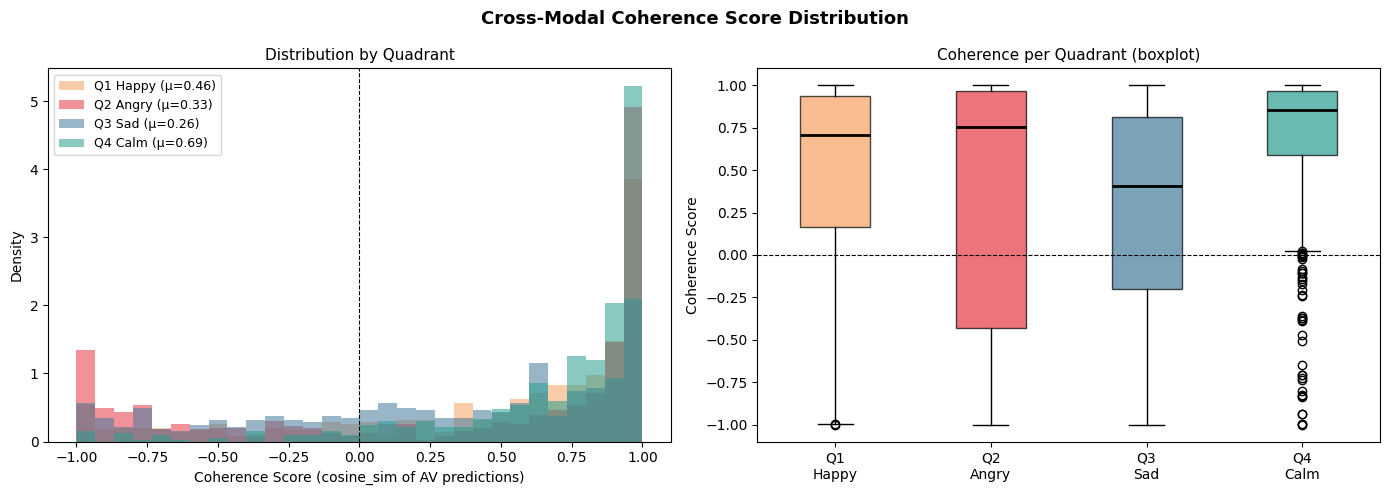

Saved: coherence_distribution.png


In [10]:
coh_df = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_scores.parquet'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Cross-Modal Coherence Score Distribution', fontsize=13, fontweight='bold')

# Left: histogram by quadrant
ax = axes[0]
for q, color in QUADRANT_COLORS.items():
    vals = coh_df[coh_df['quadrant'] == q]['coherence_score']
    ax.hist(vals, bins=30, alpha=0.55, color=color,
            label=f'{q} {QUADRANT_LABELS[q]} (μ={vals.mean():.2f})', density=True)
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax.set_xlabel('Coherence Score (cosine_sim of AV predictions)', fontsize=10)
ax.set_ylabel('Density', fontsize=10)
ax.set_title('Distribution by Quadrant', fontsize=11)
ax.legend(fontsize=9)

# Right: boxplot
ax = axes[1]
data  = [coh_df[coh_df['quadrant'] == q]['coherence_score'].values for q in ['Q1','Q2','Q3','Q4']]
bplot = ax.boxplot(data, patch_artist=True, notch=False,
                   medianprops=dict(color='black', linewidth=2))
for patch, q in zip(bplot['boxes'], ['Q1','Q2','Q3','Q4']):
    patch.set_facecolor(QUADRANT_COLORS[q])
    patch.set_alpha(0.7)
ax.set_xticklabels([f'{q}\n{QUADRANT_LABELS[q]}' for q in ['Q1','Q2','Q3','Q4']])
ax.set_ylabel('Coherence Score', fontsize=10)
ax.set_title('Coherence per Quadrant (boxplot)', fontsize=11)
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coherence_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: coherence_distribution.png')

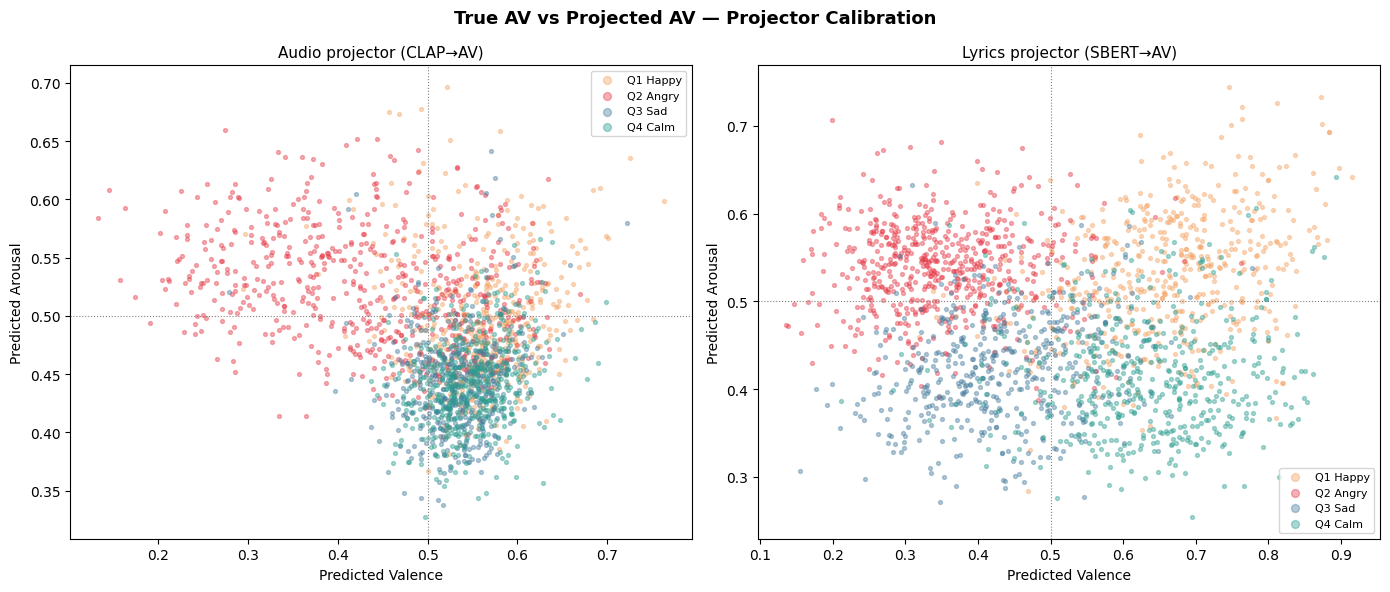

Saved: av_projection.png


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('True AV vs Projected AV — Projector Calibration', fontsize=13, fontweight='bold')

for ax, (pred_a, pred_v, title) in zip(axes, [
    (coh_df['av_audio_arousal'],  coh_df['av_audio_valence'],  'Audio projector (CLAP→AV)'),
    (coh_df['av_lyrics_arousal'], coh_df['av_lyrics_valence'], 'Lyrics projector (SBERT→AV)'),
]):
    for q, color in QUADRANT_COLORS.items():
        mask = coh_df['quadrant'] == q
        ax.scatter(pred_v[mask], pred_a[mask], c=color, s=8, alpha=0.4,
                   label=f'{q} {QUADRANT_LABELS[q]}')
    ax.set_xlabel('Predicted Valence', fontsize=10)
    ax.set_ylabel('Predicted Arousal', fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.legend(fontsize=8, markerscale=2)
    ax.axhline(0.5, color='gray', linestyle=':', linewidth=0.8)
    ax.axvline(0.5, color='gray', linestyle=':', linewidth=0.8)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'av_projection.png'), dpi=150, bbox_inches='tight')
plt.show()
print('Saved: av_projection.png')

In [12]:
# Load merged dataset for artist/title metadata
merged = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
paradoxes = coh_df.nsmallest(15, 'coherence_score').merge(
    merged[['song_id','artist','title']], on='song_id', how='left'
)

print('Top-15 Emotional Paradoxes (lowest cross-modal coherence)')
print('=' * 80)
print(f'{"Rank":<5} {"Coherence":>10}  {"Q":>2}  {"Artist":<25} {"Title"}')
print('-' * 80)
for rank, (_, row) in enumerate(paradoxes.iterrows(), 1):
    artist = str(row.get('artist', '?'))[:24]
    title  = str(row.get('title',  '?'))[:30]
    print(f'{rank:<5} {row["coherence_score"]:>10.4f}  {row["quadrant"]:>2}  {artist:<25} {title}')

print()
print('Top-15 Most Coherent Tracks (audio & lyrics agree most strongly)')
print('=' * 80)
coherent = coh_df.nlargest(15, 'coherence_score').merge(
    merged[['song_id','artist','title']], on='song_id', how='left'
)
print(f'{"Rank":<5} {"Coherence":>10}  {"Q":>2}  {"Artist":<25} {"Title"}')
print('-' * 80)
for rank, (_, row) in enumerate(coherent.iterrows(), 1):
    artist = str(row.get('artist', '?'))[:24]
    title  = str(row.get('title',  '?'))[:30]
    print(f'{rank:<5} {row["coherence_score"]:>10.4f}  {row["quadrant"]:>2}  {artist:<25} {title}')

Top-15 Emotional Paradoxes (lowest cross-modal coherence)
Rank   Coherence   Q  Artist                    Title
--------------------------------------------------------------------------------
1        -1.0000  Q2  Black Sabbath             The Writ
2        -1.0000  Q2  D12                       Words Are Weapons
3        -0.9999  Q3  Client                    Heartland
4        -0.9998  Q2  Ice Cube                  The Predator
5        -0.9998  Q1  Shakira                   Timor
6        -0.9998  Q2  Crucifucks                Artificial Girl
7        -0.9996  Q2  Syleena Johnson           The Day After
8        -0.9996  Q2  Lloyd Banks               Gilmore's
9        -0.9994  Q4  Nelly                     N Dey Say
10       -0.9993  Q2  Rage Against the Machine  Voice of the Voiceless
11       -0.9993  Q2  Heavy Heavy Low Low       Are You Okay, Kiddo?
12       -0.9993  Q1  Louis Armstrong           My Sweet Hunk O' Trash
13       -0.9986  Q2  The Notorious B.I.G.      Ready to D

In [13]:
# Sanity-check: verify saved indices can be reloaded and produce correct retrieval
print('Reloading indices from disk ...')
audio_idx_disk  = faiss.read_index(os.path.join(FAISS_DIR, 'audio_only.index'))
lyrics_idx_disk = faiss.read_index(os.path.join(FAISS_DIR, 'lyrics_only.index'))
early_idx_disk  = faiss.read_index(os.path.join(FAISS_DIR, 'early_fusion.index'))

print(f'  audio_only:   {audio_idx_disk.ntotal} vectors  dim={audio_idx_disk.d}')
print(f'  lyrics_only:  {lyrics_idx_disk.ntotal} vectors  dim={lyrics_idx_disk.d}')
print(f'  early_fusion: {early_idx_disk.ntotal} vectors  dim={early_idx_disk.d}')

# Quick retrieval smoke-test
sample_sid = mm_df['song_id'].iloc[0]
results = retrieve(sample_sid, 'early_fusion', k=5)
print(f'\nEarly-fusion top-5 for {sample_sid} ({sid_to_q[sample_sid]}):')
for sid, score, q in results:
    print(f'  {sid}  {q}  score={score:.4f}')

print('\nAll indices validated.')

Reloading indices from disk ...
  audio_only:   3232 vectors  dim=512
  lyrics_only:  2075 vectors  dim=768
  early_fusion: 2075 vectors  dim=1280

Early-fusion top-5 for A061-66 (Q3):
  MT0011650689  Q4  score=0.6508
  MT0005115042  Q3  score=0.6388
  MT0008530652  Q4  score=0.6370
  MT0012666474  Q3  score=0.6234
  MT0009319587  Q2  score=0.6225

All indices validated.


## Phase 4 Complete

### Outputs

| File | Contents |
|---|---|
| `faiss_index/audio_only.index` | CLAP normalized, 3,232 tracks, 512-dim |
| `faiss_index/lyrics_only.index` | SBERT normalized, 2,075 tracks, 768-dim |
| `faiss_index/early_fusion.index` | L2-norm([CLAP_raw; SBERT_raw]), 2,075 tracks, 1,280-dim |
| `faiss_index/*_meta.parquet` | FAISS pos → song_id, quadrant, arousal, valence |
| `coherence_scores.parquet` | coherence_score, av_audio_*, av_lyrics_* per track |

### Loading indices in Phase 5
```python
import faiss, pandas as pd, numpy as np
audio_index = faiss.read_index('outputs/faiss_index/audio_only.index')
audio_meta  = pd.read_parquet('outputs/faiss_index/audio_only_meta.parquet')
# query with normalized CLAP:
q = clap_norm_vec.reshape(1, -1).astype('float32')
faiss.normalize_L2(q)
scores, idxs = audio_index.search(q, k=10)

# early fusion query: concatenate raw projections, then normalize
early_index = faiss.read_index('outputs/faiss_index/early_fusion.index')
q_early = np.concatenate([clap_raw_vec, sbert_raw_vec]).reshape(1, -1).astype('float32')
faiss.normalize_L2(q_early)
scores, idxs = early_index.search(q_early, k=10)
```

### Late fusion at query time
```python
score(q, c) = alpha * cosine_audio(q, c) + (1 - alpha) * cosine_lyrics(q, c)
# Tune alpha ∈ {0.2, 0.4, 0.5, 0.6, 0.8} in Phase 5
```

**Next:** Phase 5 — Evaluation (`phase5_evaluation.ipynb`)